In [1]:
# Clustering and Multidimensional Scaling of Hybrid Similarity Search Results: Application to Illicit Drug Mass Spectra
# Melinda A. Kleczynski, Arun S. Moorthy, Anthony J. Kearsley

# plot MDS configurations with cluster labels 
# compare original vs MDS cluster labels 

### User selections

In [2]:
n_trials = 1000       # 1000 trials to produce the results in the manuscript; can lower to decrease run time 
dataset_number = 1    # 1, 2, 3, or 4  (see Table 1)
save_outputs = False 

### Packages

In [3]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd 

from scipy.cluster import hierarchy 
from sklearn.metrics import fowlkes_mallows_score

### Read data

In [4]:
# initially "unsorted" in the sense that we have not yet chosen the spectrum whose point we are restricting to the x-axis

unsorted_asymmetric_HSS_MFs = pd.read_csv('hitlists\\HSS' + str(dataset_number) + '.csv', header = None).to_numpy()
if np.sum(np.isnan(unsorted_asymmetric_HSS_MFs)) > 0: 
    print('Caution: nan values')
unsorted_HSS_MFs = 0.5*(unsorted_asymmetric_HSS_MFs + np.transpose(unsorted_asymmetric_HSS_MFs))  # symmetrize  
unsorted_Delta = (999 - unsorted_HSS_MFs)/999

unsorted_spectra_keys = pd.read_csv('hitlists\\key' + str(dataset_number) + '.csv', usecols = ['Name', 'NIST Number']) 

n_objects = len(unsorted_spectra_keys)

### Choose spectrum to assign to x-axis and reorder to place right after query spectrum

In [5]:
farthest_spec = int(np.argmax([np.sum(np.abs(unsorted_Delta[:, 0] - unsorted_Delta[:, i])) for i in range(n_objects)]))

In [6]:
other_indices = [i for i in range(1, n_objects) if i != farthest_spec]
for_sorting = [0] + [farthest_spec] + other_indices

In [7]:
Delta = unsorted_Delta[np.ix_(for_sorting, for_sorting)]
spectra_keys = unsorted_spectra_keys.reindex(for_sorting).reset_index(drop = True)

### Get cluster labels for original HSS dissimilarities for comparison 

In [8]:
orig_clabels = np.load('TwoStepClusterLabels\\OrigDissimClabels' + str(dataset_number) + '.npy')
n_MDS_clusters = len(np.unique(orig_clabels))

### Clustering and MDS methods

In [9]:
clustering_methods = ['complete', 'single'] 
mds_methods = ['stress', 's_stress']  

nrow = len(clustering_methods)
ncol = len(mds_methods)

### Load MDS configurations

In [10]:
def read_mds_config(mds_type):  # mds_type: 'stress' or 's_stress'

    fpath = 'configurations\\' + mds_type + '_final_' + str(dataset_number) + '_' + str(n_trials) + '.npy'

    return np.load(fpath)

In [11]:
mds_configurations = {}
for mds_method in mds_methods:
    mds_configurations[mds_method] = read_mds_config(mds_method)

### MDS cluster labels 

In [12]:
mds_clabels = {}

for clustering_method in clustering_methods:
    for mds_method in mds_methods:

        mds_config = mds_configurations[mds_method]

        hierarchical_clustering = hierarchy.linkage(mds_config, method = clustering_method, optimal_ordering = True) 
        mds_clabels[(clustering_method, mds_method)] = hierarchy.fcluster(hierarchical_clustering, n_MDS_clusters, criterion = 'maxclust')

In [13]:
if save_outputs:  

    np.save('MdsClusterLabels\\LS_STRESS_clabels_complete' + str(dataset_number) + '.npy', mds_clabels[('complete', 'stress')])
    np.save('MdsClusterLabels\\LS_STRESS_clabels_single' + str(dataset_number) + '.npy', mds_clabels[('single', 'stress')])

    np.save('MdsClusterLabels\\LS_SSTRESS_clabels_complete' + str(dataset_number) + '.npy', mds_clabels[('complete', 's_stress')])
    np.save('MdsClusterLabels\\LS_SSTRESS_clabels_single' + str(dataset_number) + '.npy', mds_clabels[('single', 's_stress')])

### Plot MDS configurations

Note: 
* We added reflections over the axes to align the MDS configurations. 
* This is for visual comparison - it does not affect the clustering results. 
* The particular reflections used are arbitrary. We show all four possibilities. 

In [14]:
scatter_colors = ['#000000', '#E49F00', '#56B4EB', '#00A073']
scatter_markers = ['d', 'o', 's', '^']

In [15]:
# for reflection 

x_refl_index = 1 
y_refl_index = np.argmax(mds_configurations['stress'][:, 1]) 

orig_x_sign = np.sign(mds_configurations['stress'][x_refl_index, 0])
orig_y_sign = np.sign(mds_configurations['stress'][y_refl_index, 1])

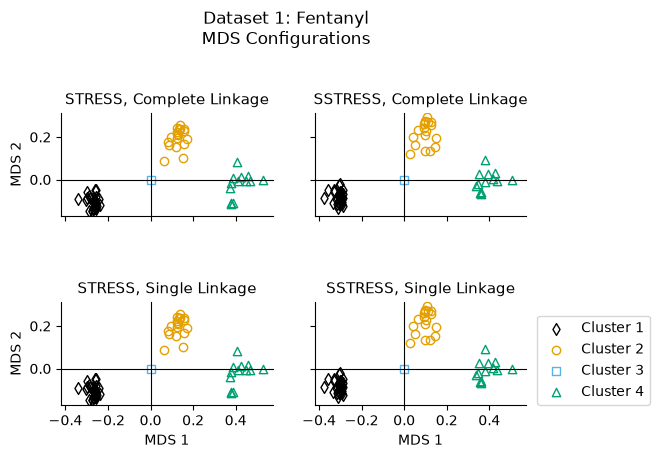

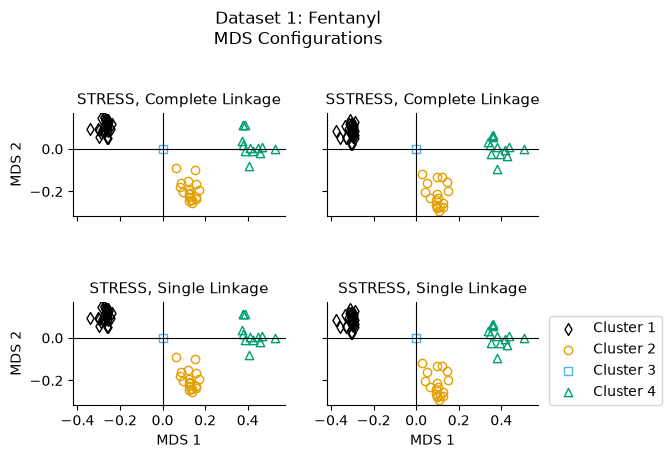

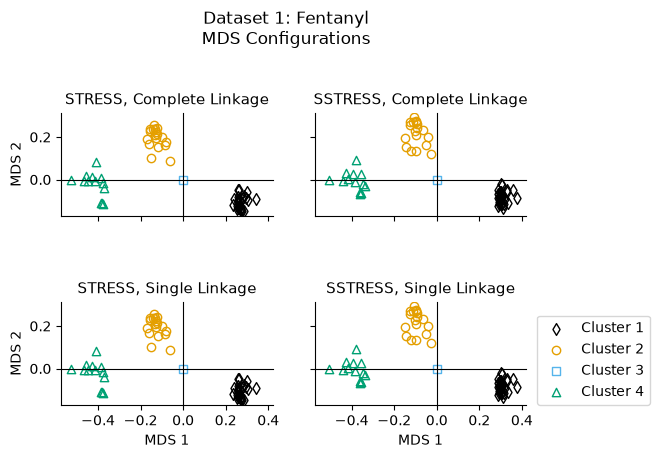

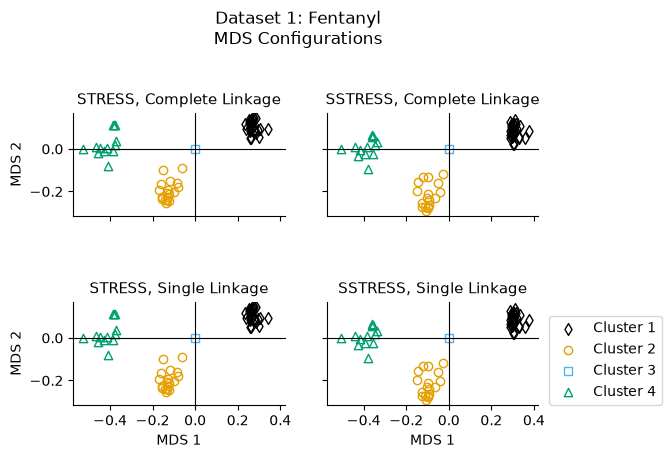

In [16]:
for x_r in [-1, 1]:  # different options for reflections 
    for y_r in [-1, 1]:

        fig, ax = plt.subplots(nrow, ncol, figsize = (6, 4.5), sharex = True, sharey = True)  

        for row in range(nrow):

            clustering_method = clustering_methods[row]

            for col in range(ncol):  

                mds_method = mds_methods[col]
                mds_config = mds_configurations[mds_method]
                clabels = mds_clabels[(clustering_method, mds_method)]

                # reflection 
                x_sign = np.sign(mds_config[x_refl_index, 0])
                y_sign = np.sign(mds_config[y_refl_index, 1])
                mds_config[:, 0]*=(orig_x_sign*x_sign*x_r)
                mds_config[:, 1]*=(orig_y_sign*y_sign*y_r)

                for c in np.unique(clabels):
                    ax[row, col].scatter(mds_config[clabels == c, 0], mds_config[clabels == c, 1], 
                                        edgecolors = scatter_colors[c-1], color = (0, 0, 0, 0),
                                        marker = scatter_markers[c-1],
                                        label = 'Cluster ' + str(c))

                ax[row, col].set_aspect('equal') 
                ax[row, col].spines['top'].set_position('zero')
                ax[row, col].spines['right'].set_position('zero')
                ax[row, col].set_title(mds_method.replace('_', '').upper() + ', ' + clustering_method[0].upper() + clustering_method[1:] + ' Linkage', fontsize = 11)

                if row == nrow-1:
                    ax[row, col-1].set_xlabel('MDS 1')
                if col == 0:
                    ax[row, col].set_ylabel('MDS 2') 

        ax[1, 1].legend(loc = (1.05, 0))

        plt.suptitle('Dataset ' + str(dataset_number) + ': ' + spectra_keys['Name'].iloc[0] + '\nMDS Configurations', y = 1.05)

        plt.show()

### Compare original vs MDS cluster labels

In [17]:
print('Fowlkes-Mallows Index for clustering of original dissimilarities versus MDS configurations')

for clustering_method in clustering_methods:

    for mds_method in mds_methods:

        clustering_score = fowlkes_mallows_score(orig_clabels, mds_clabels[(clustering_method, mds_method)])

        if clustering_score == 1:
            printable_clustering_score = '%.2f' %clustering_score
        else:
            printable_clustering_score = '%.3f' %clustering_score

        print(clustering_method, mds_method, printable_clustering_score)

Fowlkes-Mallows Index for clustering of original dissimilarities versus MDS configurations
complete stress 1.00
complete s_stress 1.00
single stress 1.00
single s_stress 1.00
